# Capítulo 3 · Proyecto: preparar los datos del Titanic

**EDA, limpieza, transformación y escalado**

**Integrantes:** Oscar Gomez Vasquez, 
Gustavo Emir Jimenez Cruz, 
Eros Arturo Garcia Acosta, 
Fernando Martinez Gomez.

| Fase | Tiempo |
|---|---|
| 1 · Primer contacto | 20 min |
| 2 · Análisis exploratorio | 40 min |
| 3 · Limpieza | 65 min |
| 4 · Transformación y escalado | 40 min |
| 5 · Bitácora y conclusiones | 15 min |

**Reglas:** funciona con *Restart & Run All* · imports al inicio · rutas relativas (`data/titanic.csv`) · `random_state=42` · cada gráfica lleva 1–2 frases de interpretación · limpia las salidas antes de hacer commit.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

SEED = 42
np.random.seed(SEED)

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

df = pd.read_csv(DATA_DIR / "titanic.csv")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


| Columna | Significado | Columna | Significado |
|---|---|---|---|
| `survived` | Objetivo (0 = no, 1 = sí) | `class` | Clase, en texto |
| `pclass` | Clase: 1, 2 o 3 | `who` | Hombre, mujer o niño |
| `sex` | Sexo | `adult_male` | ¿Hombre adulto? |
| `age` | Edad en años | `deck` | Cubierta del camarote |
| `sibsp` | Hermanos / cónyuges a bordo | `embark_town` | Puerto, en texto |
| `parch` | Padres / hijos a bordo | `alive` | ¿Sobrevivió?, en texto |
| `fare` | Precio del billete (£) | `alone` | ¿Viajaba solo? |
| `embarked` | Puerto: C, Q o S | | |

> Ojo: algunas columnas esconden sorpresas.

---
## 1 · Primer contacto *(20 min)*

**Mira antes de tocar.** El objetivo es conocer el dataset, no arreglarlo.

- [ ] Primeras y últimas filas, `shape` y tipos de dato.

In [2]:
df.shape

(891, 15)

In [3]:
df.head(5)

df.tail

<bound method NDFrame.tail of      survived  pclass     sex   age  sibsp  parch     fare embarked   class  \
0           0       3    male  22.0      1      0   7.2500        S   Third   
1           1       1  female  38.0      1      0  71.2833        C   First   
2           1       3  female  26.0      0      0   7.9250        S   Third   
3           1       1  female  35.0      1      0  53.1000        S   First   
4           0       3    male  35.0      0      0   8.0500        S   Third   
..        ...     ...     ...   ...    ...    ...      ...      ...     ...   
886         0       2    male  27.0      0      0  13.0000        S  Second   
887         1       1  female  19.0      0      0  30.0000        S   First   
888         0       3  female   NaN      1      2  23.4500        S   Third   
889         1       1    male  26.0      0      0  30.0000        C   First   
890         0       3    male  32.0      0      0   7.7500        Q   Third   

       who  adult_mal

In [4]:
df.dtypes

survived         int64
pclass           int64
sex                str
age            float64
sibsp            int64
parch            int64
fare           float64
embarked           str
class              str
who                str
adult_male        bool
deck               str
embark_town        str
alive              str
alone             bool
dtype: object

- [ ] Resumen estadístico de las numéricas y de las categóricas.

In [5]:
df.describe(exclude="number")


,sex,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891,889,891,891,891,203,889,891,891
unique,2,3,3,3,2,7,3,2,2
top,male,S,Third,man,True,C,Southampton,no,True
freq,577,644,491,537,537,59,644,549,537


In [6]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


- [ ] Faltantes por columna (número y %), filas duplicadas y valores únicos de cada categórica.

In [7]:
df.nunique()

survived         2
pclass           3
sex              2
age             88
sibsp            7
parch            7
fare           248
embarked         3
class            3
who              3
adult_male       2
deck             7
embark_town      3
alive            2
alone            2
dtype: int64

In [8]:
faltantes = df.isna().sum()
porcentaje = (df.isna().mean() * 100).round(1)
pd.DataFrame({"faltantes": faltantes, "%": porcentaje})

,faltantes,%
survived,0,0.0
pclass,0,0.0
sex,0,0.0
age,177,19.9
sibsp,0,0.0
parch,0,0.0
fare,0,0.0
embarked,2,0.2
class,0,0.0
who,0,0.0


In [9]:
df.duplicated().sum()

np.int64(107)

### Preguntas de la fase 1

1. ¿Es un problema de clasificación o de regresión? ¿Por qué?
2. ¿Qué columna numérica se comporta como categórica? ¿Y qué categórica tiene orden?
3. ¿Qué parejas de columnas dicen lo mismo? **Compruébalo** con código, no a ojo.
4. ¿Qué pasa si le das `alive` al modelo?

✍️ **Tus respuestas:**

1. Es un problema de clasificacion, debido a que se hace un conteo y agrupamiento de los grupos sobrevivientes.
2. Survived y Pclass son columnas numericas que se comportan como categoricas; Class es una variable categorica que si tiene orden.
3. Como se observa en los codigos de abajo, existen 3 pares de columna identicas.
4. Habra que transformar el str a int, por lo tanto no lo digiere.

In [10]:
df.groupby("survived")["alive"].unique()

survived
0     [no]
1    [yes]
Name: alive, dtype: object

In [11]:
df.groupby("pclass")["class"].unique()

pclass
1     [First]
2    [Second]
3     [Third]
Name: class, dtype: object

In [12]:
df.groupby("embarked")["embark_town"].unique()

embarked
C      [Cherbourg]
Q     [Queenstown]
S    [Southampton]
Name: embark_town, dtype: object

---
## 2 · Análisis exploratorio *(40 min)*

**Cada gráfica lleva 1–2 frases de interpretación. Sin interpretación, no cuenta.**

### Objetivo y univariado

- [ ] % de supervivientes: ¿clases equilibradas?

In [13]:
df["survived"].value_counts(normalize=True) * 100

survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

## ✍️Respuesta: 
Obtuvimos el conteo de la columna "Survived" para obtener el porcentaje de acuerdo a cada valor binario, viendo los porcentajes 0(Murio) = 61% y 1(Sobrevivio) = 38%, se concluye que las clases estan desequilibradas.

- [ ] Histograma y boxplot de `age` y `fare`.

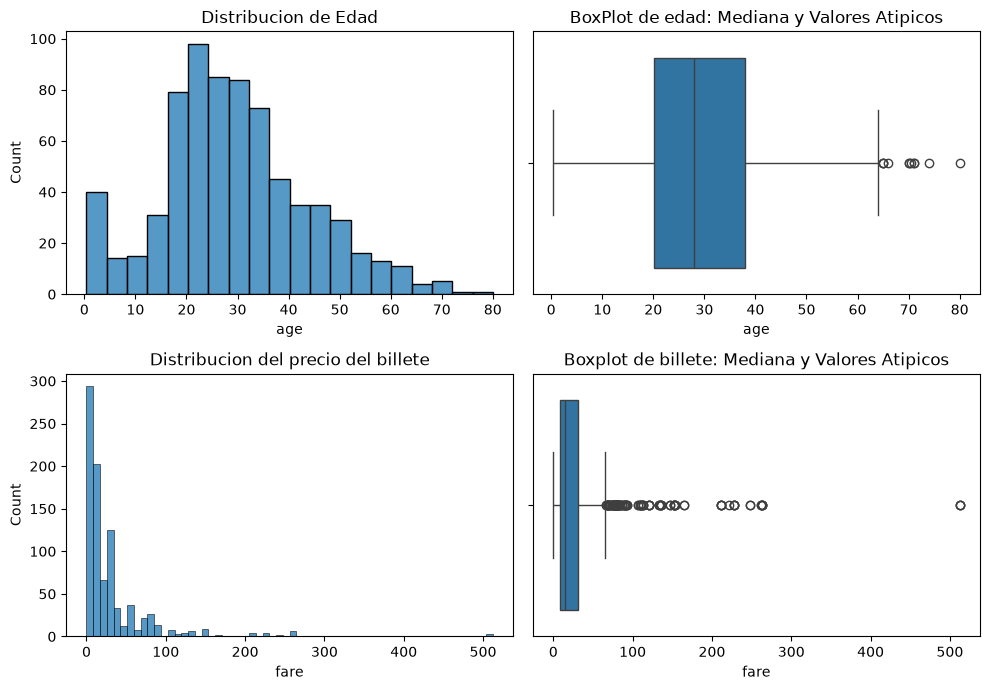

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
sns.histplot(df["age"], ax=axes[0, 0]) 
axes[0, 0].set_title("Distribucion de Edad")
sns.boxplot(x=df["age"], ax=axes[0, 1])
axes[0, 1].set_title("BoxPlot de edad: Mediana y Valores Atipicos")
sns.histplot(df["fare"], ax=axes[1, 0])
axes[1, 0].set_title("Distribucion del precio del billete")
sns.boxplot(x=df["fare"], ax=axes[1, 1])
axes[1, 1].set_title("Boxplot de billete: Mediana y Valores Atipicos")
plt.tight_layout()
plt.show()

## Razonamiento de las graficas
En el histograma de edad, la mayoria de personas promedian 28 y son menores de 40, hay una minoria de personas en la vejez.
En el boxplot de edad, la mediana esta en 28 años y tenemos valores atipicos a partir de los 60 años.

En el histograma del precio del billete, los precios estan condensados entre 0 y 50, y la minoria de billetes cuesta mas de 100.
En el boxplot la mediana esta en aprox. 10, con muchos valores atipicos a partir de los 70.

## ✍️ Respuesta


- [ ] Barras de `sex`, `pclass`, `embarked`, `sibsp` y `parch`.

✍️ **Respuesta / interpretación:** (qué haces y por qué)

### Frente a `survived`

- [ ] Supervivencia por sexo, clase, edad, `fare` y `alone`.

In [15]:
# Tu código aquí

✍️ **Respuesta / interpretación:** (qué haces y por qué)

- [ ] ¿Influyó el puerto? **Antes de concluir, cruza puerto con clase.**

In [16]:
# Tu código aquí

✍️ **Respuesta / interpretación:** (qué haces y por qué)

- [ ] Mujeres de 3.ª clase vs. hombres de 1.ª.

In [17]:
# Tu código aquí

✍️ **Respuesta / interpretación:** (qué haces y por qué)

### Preguntas de la fase 2

- Si solo pudieras usar **una** columna para predecir, ¿cuál y por qué?
- Tres hallazgos que te sorprendan.
- ¿Algo huele a error en los datos?

✍️ **Tus respuestas:**

- 
- 
-

---
## 3 · Limpieza *(65 min)*

- [ ] **Copia:** guarda los datos originales antes de tocar nada.

In [18]:
# Tu código aquí

- [ ] **Redundancia y fuga:** elimina columnas repetidas. ¿Qué haces con `who` y `adult_male`? ¿Qué columna provoca *data leakage*?

In [19]:
# Tu código aquí

✍️ **Respuesta / interpretación:** (qué haces y por qué)

- [ ] **Duplicados:** no hay nombre ni billete. ¿Son errores o personas distintas?

In [20]:
# Tu código aquí

✍️ **Respuesta / interpretación:** (qué haces y por qué)

- [ ] **Faltantes:** decide para `deck`, `age` y `embarked`. ¿Eliminar, media, mediana por grupo, moda o indicador?

In [21]:
# Tu código aquí

✍️ **Respuesta / interpretación:** (qué haces y por qué)

- [ ] **Outliers:** revisa `fare`, `age`, `sibsp` y `parch` con IQR y Z-score. ¿Error o valor raro pero real?

In [22]:
# Tu código aquí

✍️ **Respuesta / interpretación:** (qué haces y por qué)

- [ ] **Antes vs. después:** compara filas, faltantes, distribuciones y % de supervivientes.

In [23]:
# Tu código aquí

✍️ **Respuesta / interpretación:** (qué haces y por qué)

**Pregunta clave:** billetes de 0 £ y de más de 500 £, edades menores de 1 año, 8 hermanos a bordo. ¿Los eliminarías?

✍️ **Tu respuesta:**

---
## 4 · Transformación y escalado *(40 min)*

- [ ] **Feature engineering:** crea ≥ 2 variables (p. ej. tamaño de familia, tramos de edad) y valida cada una contra `survived`.

In [24]:
# Tu código aquí

✍️ **Respuesta / interpretación:** (qué haces y por qué)

- [ ] **Asimetría:** aplica log a la variable que lo necesite. ¿Qué haces con los ceros?

In [25]:
# Tu código aquí

✍️ **Respuesta / interpretación:** (qué haces y por qué)

- [ ] **Codificación:** nominal → one-hot, ordinal → ordinal. ¿`pclass` como número o one-hot? ¿Cuándo usar `drop="first"`?

In [26]:
# Tu código aquí

✍️ **Respuesta / interpretación:** (qué haces y por qué)

- [ ] **Split:** 80/20 estratificado, `random_state=42`. Verifica el % de supervivientes en ambos.

In [27]:
# Tu código aquí

✍️ **Respuesta / interpretación:** (qué haces y por qué)

- [ ] **Escalado:** `StandardScaler` o `MinMaxScaler` según la forma y los outliers. `fit` **solo con train**.

In [28]:
# Tu código aquí

✍️ **Respuesta / interpretación:** (qué haces y por qué)

- [ ] **Bonus:** todo en un `ColumnTransformer` dentro de un `Pipeline`.

In [29]:
# Tu código aquí

**Pregunta clave:** ¿en qué orden van *split*, imputación y escalado? ¿Qué pasa si calculas la mediana de `age` con todos los datos, incluido test?

✍️ **Tu respuesta:**

### Verificación final

- [ ] Sin faltantes
- [ ] Todo numérico
- [ ] Mismas columnas en `X_train` y `X_test`
- [ ] Sin `survived` ni columnas que la revelen
- [ ] `shape` de los cuatro conjuntos (`X_train`, `X_test`, `y_train`, `y_test`)

In [30]:
# Tu código aquí

---
## 5 · Bitácora y conclusiones *(15 min)*

### Bitácora · una fila por decisión

Mínimo: columnas eliminadas, duplicados, cada faltante, cada outlier, cada variable nueva, codificación y escalado.

| # | Columna | Problema | Opciones | Decisión | Por qué | Afectados |
|---|---------|----------|----------|----------|---------|-----------|
| 1 | *ejemplo* | 5 % faltantes | Eliminar, media, mediana | Mediana | Distribución asimétrica | 45 |
| 2 |  |  |  |  |  |  |
| 3 |  |  |  |  |  |  |
| 4 |  |  |  |  |  |  |
| 5 |  |  |  |  |  |  |

### Conclusiones

- **Los 3 factores que más influyeron:**
- **Mi decisión más difícil y qué pasaría con otra:**
- **Qué dato me faltó:**
- **Forma final y columnas que verá el modelo:**